# Multiple linear regression

A comparison of vehicle-weight and engine-volume predictors, including coefficient sensitivity and held-out prediction error.

## Data and scope

The analysis uses 36 vehicle observations, with Weight and Volume as predictors and CO2 as the response. The fitted coefficients and predictions reproduce the reference results. Weight is expressed in kg and Volume in cm³; CO2 is reported in dataset units because its measurement metadata are unspecified. The sample is used to examine model behaviour, not to estimate emissions for the wider vehicle population.

Dataset: [module-4-machine-learning_correlation-and-regression-cars.csv](module-4-machine-learning_correlation-and-regression-cars.csv).


## Environment

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scipy', scipy.__version__, 'sklearn', sklearn.__version__)
results = {}

numpy 2.4.4 pandas 3.0.2 scipy 1.17.1 sklearn 1.8.0


## Baseline analysis

In [2]:
import pandas
from sklearn import linear_model
df = pandas.read_csv('module-4-machine-learning_correlation-and-regression-cars.csv')
X = df[['Weight', 'Volume']]
y = df['CO2']
regr = linear_model.LinearRegression()
regr.fit(X, y)
predictedCO2 = regr.predict(pandas.DataFrame([[2300, 1300]], columns=X.columns))
print(predictedCO2)

[107.2087328]


In [3]:
print(regr.coef_)

[0.00755095 0.00780526]


In [4]:
predictedCO2 = regr.predict(pandas.DataFrame([[3300, 1300]], columns=X.columns))
print(predictedCO2)

[114.75968007]


## Sensitivity analysis

Ordinary least squares is fitted with both predictors and with each predictor separately. Leave-one-out validation refits each model on 35 rows and predicts the omitted row. Additional comparisons vary prediction inputs and increase the final training response from 120 to 150 before refitting.

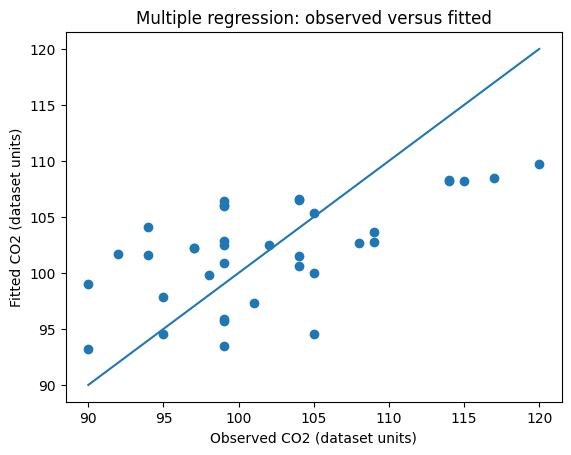

In [5]:
from scipy.stats import pearsonr, linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
df = pd.read_csv('module-4-machine-learning_correlation-and-regression-cars.csv')
X = df[['Weight', 'Volume']]
y = df.CO2
model = LinearRegression().fit(X, y)
assert np.allclose(model.coef_, [0.00755095, 0.00780526], atol=1e-08)
assert np.isclose(model.predict(pd.DataFrame([[2300, 1300]], columns=X.columns))[0], 107.2087328)
results['multiple'] = {'n': len(df), 'range': {c: [float(X[c].min()), float(X[c].max())] for c in X}, 'intercept': float(model.intercept_), 'coefficients': model.coef_.tolist(), 'r2': float(model.score(X, y)), 'predictor_r': float(X.corr().iloc[0, 1])}
for name, cols in [('Weight only', ['Weight']), ('Volume only', ['Volume']), ('Both', ['Weight', 'Volume'])]:
    m = LinearRegression().fit(X[cols], y)
    cv = cross_val_predict(LinearRegression(), X[cols], y, cv=LeaveOneOut())
    results['multiple'][name] = {'r2': float(m.score(X[cols], y)), 'loocv_rmse': float(np.sqrt(mean_squared_error(y, cv)))}
results['multiple']['predictions'] = {str(row): float(model.predict(pd.DataFrame([row], columns=X.columns))[0]) for row in [[2300, 1300], [3300, 1300], [2300, 2300]]}
changed = y.copy()
changed.iloc[-1] += 30
altered = LinearRegression().fit(X, changed)
results['multiple']['last CO2 +30'] = {'coefficients': altered.coef_.tolist(), 'r2': float(altered.score(X, changed)), 'prediction': float(altered.predict(pd.DataFrame([[2300, 1300]], columns=X.columns))[0])}
fig, ax = plt.subplots()
ax.scatter(y, model.predict(X))
ax.plot([90, 120], [90, 120])
ax.set(xlabel='Observed CO2 (dataset units)', ylabel='Fitted CO2 (dataset units)', title='Multiple regression: observed versus fitted')
plt.show()

## Results

R² values describe training fit. Where reported, leave-one-out RMSE measures held-out error in response units; lower values indicate smaller errors.

In [6]:
m = results['multiple']
display(pd.DataFrame({k: m[k] for k in ['Weight only', 'Volume only', 'Both']}).T.rename(columns={'r2':'Training R²','loocv_rmse':'Leave-one-out RMSE'}).round(4))
display(pd.DataFrame({'Predicted CO2':m['predictions']}).rename_axis('Input [Weight, Volume]').round(4))
display(pd.DataFrame({'Baseline':[m['coefficients'][0],m['coefficients'][1],m['predictions']['[2300, 1300]']], 'Final CO2 +30':[m['last CO2 +30']['coefficients'][0],m['last CO2 +30']['coefficients'][1],m['last CO2 +30']['prediction']]},index=['Weight coefficient','Volume coefficient','Prediction at [2300, 1300]']).round(6))

,Training R²,Leave-one-out RMSE
Weight only,0.3049,6.4960
Volume only,0.3506,6.3061
Both,0.3766,6.5079


,Predicted CO2
"Input [Weight, Volume]",
"[2300, 1300]",107.2087
"[3300, 1300]",114.7597
"[2300, 2300]",115.0140


,Baseline,Final CO2 +30
Weight coefficient,0.007551,-0.003079
Volume coefficient,0.007805,0.017827
"Prediction at [2300, 1300]",107.208733,94.212066


## Interpretation and limitations

The two-predictor model has training R² of 0.3766, but its leave-one-out RMSE of 6.5079 exceeds the Volume-only error of 6.3061. Better training fit therefore does not translate into lower validation error. Increasing the final response reverses the Weight coefficient, indicating sensitivity to the sample. Predictor correlation (r = 0.7535) also complicates coefficient interpretation. The 2300 kg and 3300 kg examples exceed the observed maximum of 1746 kg; their predictions are extrapolations, not validated emissions estimates.

## Reproducibility

Cells were executed sequentially in an independent Python namespace. Outputs and plots are embedded, and library versions are recorded above. Analysis and editorial preparation used AI assistance.